# TD 1.2 Prédiction sur des données médicales brutes

Dans ce TD, nous allons enfin faire du vrai apprentissage. Pour cela, nous allons prendre la base classique de *Indian Diabete* (qui n'est pas sur le diabète des Indiens, mais sur les données d'une compagnie d'assurance aux US qui porte ce nom).

Nous avons en entrée un table de 9 valeurs, dont les 8 premières colonnes correspondent aux données biologiques des patients et la dernière colonne correspond à la sortie à prédire (diabète / Pas diabète).

- Chargez la table et affichez les trois premières lignes

In [5]:
!wget https://www.labri.fr/perso/lsimon/static/inge2-ia/pima-indians-diabetes.data

--2026-04-23 20:34:44--  https://www.labri.fr/perso/lsimon/static/inge2-ia/pima-indians-diabetes.data
Resolving www.labri.fr (www.labri.fr)... 147.210.8.54
Connecting to www.labri.fr (www.labri.fr)|147.210.8.54|:443... connected.
HTTP request sent, awaiting response... 200 OK
Length: 23279 (23K)
Saving to: ‘pima-indians-diabetes.data.2’

pima-indians-diabet 100%[===================>]  22.73K  --.-KB/s    in 0.005s  

2026-04-23 20:34:44 (4.06 MB/s) - ‘pima-indians-diabetes.data.2’ saved [23279/23279]



In [3]:
import matplotlib.pyplot as plt
%matplotlib inline
import numpy as np
import pandas as pd
import sklearn as sk
import sklearn.preprocessing as skp


# fix random seed for reproducibility
seed = 7
np.random.seed(seed)

# load pima indians dataset
dataset = np.loadtxt("pima-indians-diabetes.data", delimiter=",")
# split into input (X) and output (Y) variables
print(dataset.shape)
print(dataset[:3,:])

(768, 9)
[[  6.    148.     72.     35.      0.     33.6     0.627  50.      1.   ]
 [  1.     85.     66.     29.      0.     26.6     0.351  31.      0.   ]
 [  8.    183.     64.      0.      0.     23.3     0.672  32.      1.   ]]


## Estimer la distribution des valeurs

- Lisez et commentez la distribution des valeurs. Nous les representons grâce à la bibliothèque `Pandas` et la méthode `violinplot()` permettant d'estimer la distribution des valeurs par colonne. L'idée est d'aider l'apprentissage en explorant l'étendue des valeurs et leurs distributions

268 / 768


<Figure size 640x480 with 0 Axes>

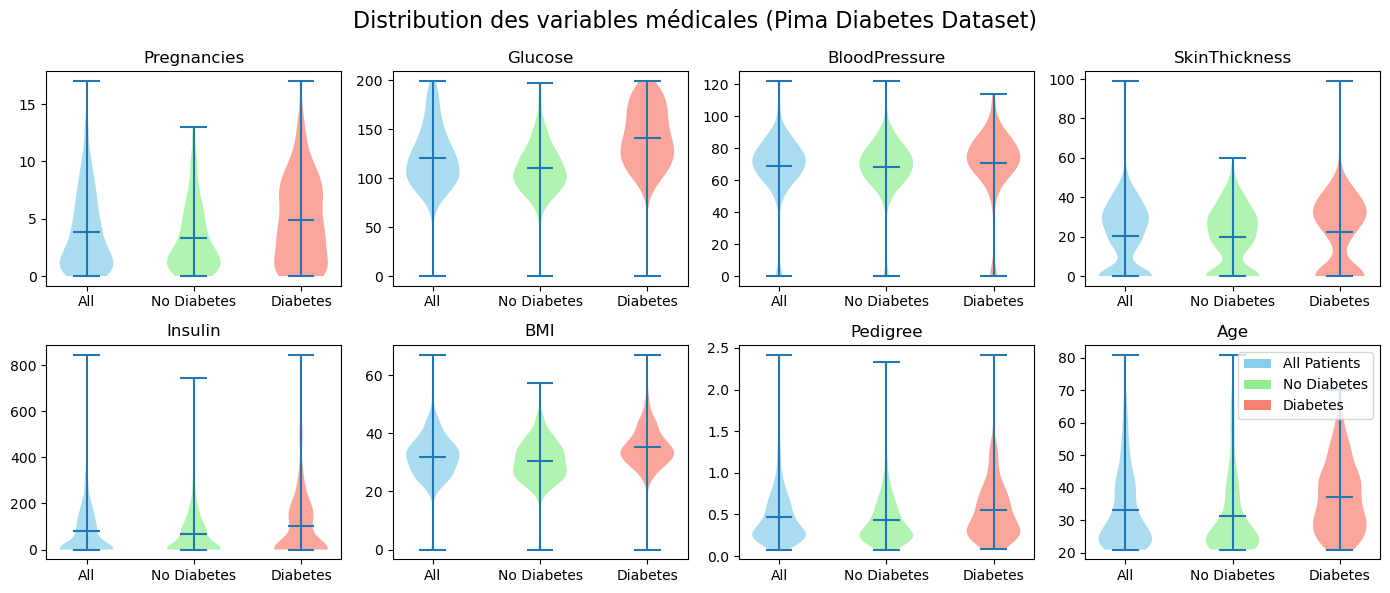

In [4]:
print(int(sum(dataset[:,8])),"/",len(dataset[:,1]))

plt.clf()
fig, ax = plt.subplots(2,4, figsize=(14,6))

features = [
"Pregnancies",
"Glucose",
"BloodPressure",
"SkinThickness",
"Insulin",
"BMI",
"Pedigree",
"Age"
]

for i in range(8):

    a = ax[i//4, i%4]

    all_data = dataset[:,i]
    no_diab = [x[i] for x in dataset if x[8]==0]
    diab = [x[i] for x in dataset if x[8]==1]

    vp = a.violinplot([all_data, no_diab, diab], positions=[1,2,3], showmeans=True)

    colors = ['skyblue','lightgreen','salmon']

    for body, color in zip(vp['bodies'], colors):
        body.set_facecolor(color)
        body.set_alpha(0.7)

    a.set_xticks([1,2,3])
    a.set_xticklabels(["All","No Diabetes","Diabetes"])
    a.set_title(features[i])

plt.suptitle("Distribution des variables médicales (Pima Diabetes Dataset)", fontsize=16)

from matplotlib.patches import Patch

legend_elements = [
Patch(facecolor='skyblue', label='All Patients'),
Patch(facecolor='lightgreen', label='No Diabetes'),
Patch(facecolor='salmon', label='Diabetes')
]

plt.legend(handles=legend_elements, loc='upper right')

plt.tight_layout()
plt.show()

## Matrice de corrélation

- Vérifiez, en utilisant Pandas, que la matrice de corrélation des valeurs ne fait pas apparaître de valeurs en trop (qui seraient corrélées)

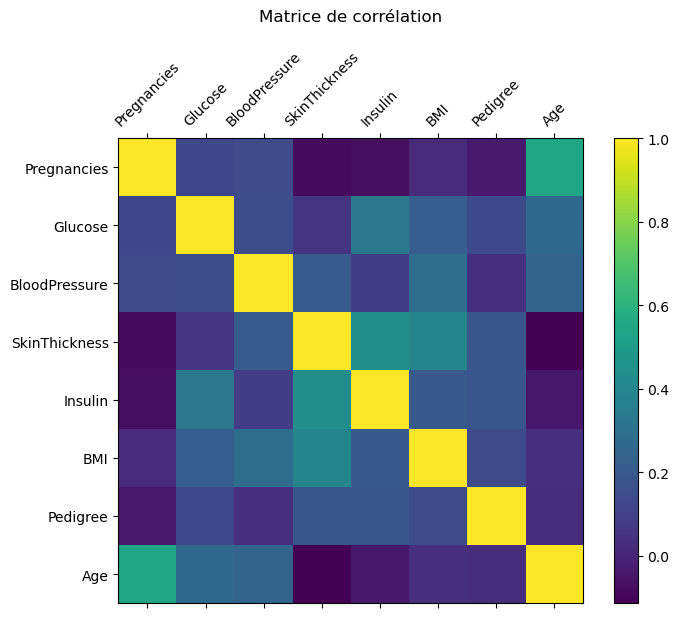

In [9]:
features = [
"Pregnancies",
"Glucose",
"BloodPressure",
"SkinThickness",
"Insulin",
"BMI",
"Pedigree",
"Age"
]

pdataset = pd.DataFrame(dataset[:,:8], columns=features)

plt.figure(figsize=(8,6))
plt.matshow(pdataset.corr(), fignum=1)
plt.xticks(range(8), features, rotation=45)
plt.yticks(range(8), features)

plt.colorbar()
plt.title("Matrice de corrélation", pad=20)

plt.show()

## Normalisez les données (par colonne)

- Utilisez la méthode `scale` de scikit learn pour normaliser les données. Représentez de nouveau les violin plots une fois normalisés

<Figure size 800x550 with 0 Axes>

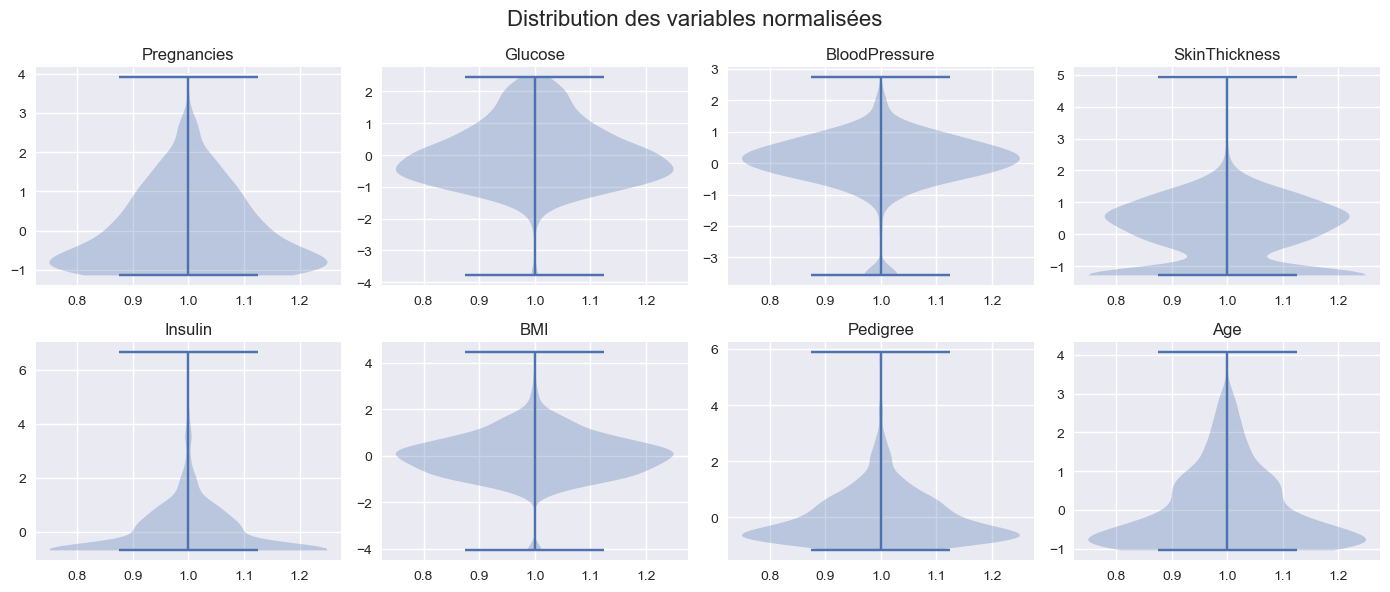

In [14]:
import matplotlib.pyplot as plt
import sklearn.preprocessing as skp

plt.clf()

XNormalized = skp.scale(dataset[:,:8]) 

features = [
"Pregnancies",
"Glucose",
"BloodPressure",
"SkinThickness",
"Insulin",
"BMI",
"Pedigree",
"Age"
]

fig, ax = plt.subplots(2,4, figsize=(14,6))

for i in range(8):
    a = ax[i//4, i%4]
    a.violinplot(XNormalized[:,i])
    a.set_title(features[i])

plt.suptitle("Distribution des variables normalisées", fontsize=16)

plt.tight_layout()
plt.show()

In [ ]:
print(XNormalized)

[[ 0.63994726  0.84832379  0.14964075 ...  0.20401277  0.46849198
   1.4259954 ]
 [-0.84488505 -1.12339636 -0.16054575 ... -0.68442195 -0.36506078
  -0.19067191]
 [ 1.23388019  1.94372388 -0.26394125 ... -1.10325546  0.60439732
  -0.10558415]
 ...
 [ 0.3429808   0.00330087  0.14964075 ... -0.73518964 -0.68519336
  -0.27575966]
 [-0.84488505  0.1597866  -0.47073225 ... -0.24020459 -0.37110101
   1.17073215]
 [-0.84488505 -0.8730192   0.04624525 ... -0.20212881 -0.47378505
  -0.87137393]]


## Equilibrez les données entre elle

- Comptez le nombre d'exemple suivant le résultat dans la dernière colonne
- Proposez une méthode permettant d'équilibrer les données

In [7]:
XNormalized = skp.scale(dataset[:,:8])
Y = dataset[:,8]

normalized_dataset = np.column_stack((XNormalized, Y))

diab = normalized_dataset[normalized_dataset[:,8] == 1]
no_diab = normalized_dataset[normalized_dataset[:,8] == 0]

extra = diab[np.random.choice(len(diab), len(no_diab)-len(diab), replace=True)]

balanced_dataset = np.vstack((normalized_dataset, extra))

print("Ancienne taille :", dataset.shape)
print("Diabétiques :", len(diab))
print("Non diabétiques :", len(no_diab))
print("Nouvelle taille :", balanced_dataset.shape)
print("Non diabétiques :", np.sum(balanced_dataset[:,8]==0))
print("Diabétiques :", np.sum(balanced_dataset[:,8]==1))

Ancienne taille : (768, 9)
Diabétiques : 268
Non diabétiques : 500
Nouvelle taille : (1000, 9)
Non diabétiques : 500
Diabétiques : 500


## Conception du réseau de neurones

- Proposez un réseau de neurones pour prédire les bonnes valeurs (inutile à ce stade de mettre trop de couches)
- Comptez à la main le nombre de paramètres que la méthode `fit` devra assigner

In [8]:
import torch
from torch import nn
from torch.utils.data import DataLoader, TensorDataset, random_split
from torch.optim import SGD, Adam

class NeuralNetwork(nn.Module):
  def __init__(self):
    super().__init__()

    self.model = nn.Sequential(
        nn.Linear(8,6),  
        nn.ReLU(),
        nn.Linear(6,1),   
        nn.Sigmoid()
    )

  def forward(self, x):
    return self.model(x)



# Training loop function
def train(tensorx, tensory, batch_size, epochs, model, criterion, optimizer, validation_split):
    train_index, valid_index = random_split(range(len(tensory)), [1-validation_split, validation_split])

    x_train, x_valid = tensorx[train_index], tensorx[valid_index]
    y_train, y_valid = tensory[train_index], tensory[valid_index]

    train_set = TensorDataset(x_train, y_train)
    valid_set = TensorDataset(x_valid, y_valid)
    train_loader = DataLoader(train_set, batch_size=batch_size, shuffle=True)
    valid_loader = DataLoader(valid_set, batch_size=batch_size, shuffle=False)

    history = {"loss":[], "val_loss":[], "score":[], "val_score":[]}
    
    for epoch in range(epochs):
    
        model.train()
        running_loss = 0
        correct = 0
        total = 0
    
        for x,y in train_loader:
    
            optimizer.zero_grad()
    
            pred = model(x)
            loss = criterion(pred, y)
    
            loss.backward()
            optimizer.step()
    
            running_loss += loss.item()
    
            pred_class = (pred > 0.5).float()
            correct += (pred_class == y).sum().item()
            total += y.size(0)
    
        train_loss = running_loss/len(train_loader)
        train_acc = correct/total

        model.eval()
        val_loss = 0
        correct_val = 0
        total_val = 0
        with torch.no_grad():
            for x,y in valid_loader:
                pred = model(x)
                loss = criterion(pred,y)
                val_loss += loss.item()
            
                pred_class = (pred > 0.5).float()
                correct_val += (pred_class == y).sum().item()
                total_val += y.size(0)

        val_loss /= len(valid_loader)
        val_acc = correct_val / total_val
        
        history["loss"].append(train_loss)
        history["val_loss"].append(val_loss)
        history["score"].append(train_acc)
        history["val_score"].append(val_acc)
        
        print(f"epoch {epoch+1} loss={train_loss:.4f} val_loss={val_loss:.4f} acc={train_acc:.4f} val_acc={val_acc:.4f}")


    return history
    
model = NeuralNetwork()

print(model)

DATAX = torch.tensor(balanced_dataset[:,:8], dtype=torch.float32)
DATAY = torch.tensor(balanced_dataset[:,8], dtype=torch.float32).view(-1,1)

batch_size = 32
epochs = 50

criterion = nn.BCELoss()

optimizer = Adam(model.parameters(), lr=0.001)

history = train(DATAX, DATAY, batch_size, epochs, model, criterion, optimizer, 0.33)



NeuralNetwork(
  (model): Sequential(
    (0): Linear(in_features=8, out_features=6, bias=True)
    (1): ReLU()
    (2): Linear(in_features=6, out_features=1, bias=True)
    (3): Sigmoid()
  )
)
epoch 1 loss=0.7456 val_loss=0.7226 acc=0.5030 val_acc=0.5121
epoch 2 loss=0.7262 val_loss=0.7079 acc=0.5030 val_acc=0.5152
epoch 3 loss=0.7105 val_loss=0.6950 acc=0.5060 val_acc=0.5303
epoch 4 loss=0.6964 val_loss=0.6843 acc=0.5134 val_acc=0.5515
epoch 5 loss=0.6841 val_loss=0.6737 acc=0.5343 val_acc=0.5879
epoch 6 loss=0.6710 val_loss=0.6634 acc=0.5657 val_acc=0.6152
epoch 7 loss=0.6578 val_loss=0.6532 acc=0.5985 val_acc=0.6182
epoch 8 loss=0.6446 val_loss=0.6425 acc=0.6284 val_acc=0.6212
epoch 9 loss=0.6303 val_loss=0.6328 acc=0.6522 val_acc=0.6273
epoch 10 loss=0.6172 val_loss=0.6227 acc=0.6836 val_acc=0.6667
epoch 11 loss=0.6034 val_loss=0.6135 acc=0.7224 val_acc=0.6667
epoch 12 loss=0.5905 val_loss=0.6056 acc=0.7284 val_acc=0.6727
epoch 13 loss=0.5783 val_loss=0.5984 acc=0.7328 val_acc=0.

## Lancez l'apprentissage !

Utilisez le code ci dessous pour lancer l'apprentissage. Vous pourrez remplacer `X` et `Y` par le nom de vos données

## Observez les courbes caractéristiques de l'apprentissage

Utilisez le code suivant pour représenter les courbes de l'apprentissage.


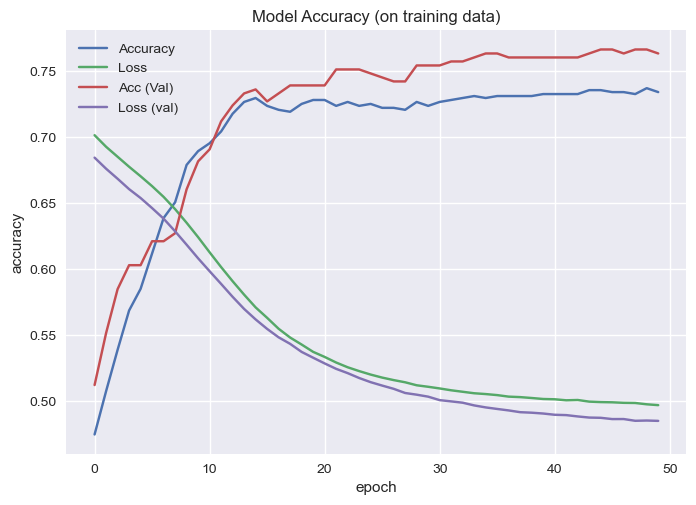

In [27]:
# Model accuracy
plt.plot(history['score'])
plt.plot(history['loss'])
plt.plot(history['val_score'])
plt.plot(history['val_loss'])
plt.title('Model Accuracy (on training data)')
plt.ylabel('accuracy')
plt.xlabel('epoch')
plt.legend(['Accuracy', 'Loss', 'Acc (Val)', 'Loss (val)'])
plt.show()


## Jouez avec les paramètres de l'apprentissage

- Ajoutez des couches et observez les qualités de l'apprentissage
- Ajoutez des couches de `Dropout()`


In [ ]:
class NeuralNetwork(nn.Module):
  def __init__(self):
    super().__init__()

    self.model = nn.Sequential(

        nn.Linear(8,16),
        nn.ReLU(),
        nn.Dropout(0.3),

        nn.Linear(16,8),
        nn.ReLU(),
        nn.Dropout(0.3),

        nn.Linear(8,1),
        nn.Sigmoid()
    )

  def forward(self, x):
    return self.model(x)